NAMA  : VANY SALSABILA PUTRI

NIM   : 123450022

KELAS : RB

TUGAS MLOPS MINGGU 6


In [2]:
!pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 974.4 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 106.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 85.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

2026/10/10 15:26:32 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/10 15:26:32 INFO mlflow.store.db.utils: Updating database tables
2026/10/10 15:26:35 INFO mlflow.tracking.fluent: Experiment with name 'bc-malignant-detection' does not exist. Creating a new experiment.
/usr/local/lib/python3.13/dist-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to inf

Model versi 1 lulus Quality Gate dan dipromosikan menjadi @champion!


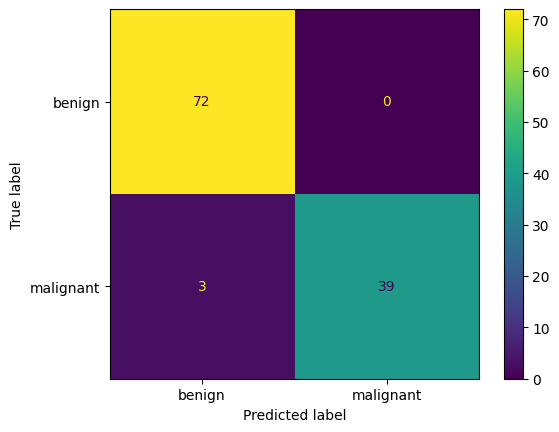

In [4]:
# ==========================================
# MLOps Hands-on: MLflow + CI/CD/CT Pipeline
# ==========================================
import hashlib
import os
import mlflow
import mlflow.data
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, classification_report
from mlflow.models import infer_signature
from mlflow import MlflowClient

# 1. Konfigurasi Tracking Server & Eksperimen (Menggunakan database SQLite lokal)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("bc-malignant-detection")

# 2. L1: Data Preparation, Splitting, dan Versioning (Hash)
df = load_breast_cancer(as_frame=True).frame
df["target"] = 1 - df["target"]  # 1 = malignant (kelas positif)

# Membuat sidik jari data (hash)
data_md5 = hashlib.md5(pd.util.hash_pandas_object(df, index=True).values).hexdigest()

os.makedirs("data", exist_ok=True)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["target"], random_state=42)
train_df.to_csv("data/train.csv", index=False)
test_df.to_csv("data/test.csv", index=False)  # Test set dikunci

X_train, y_train = train_df.drop(columns="target"), train_df["target"]
X_test, y_test = test_df.drop(columns="target"), test_df["target"]

train_ds = mlflow.data.from_pandas(train_df, source="data/train.csv", name="bc-train", targets="target")
COMMON_TAGS = {"data_md5": data_md5, "split_seed": "42", "dataset": "sklearn-breast-cancer"}

# 3. Fungsi Standar Logging Eksperimen
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = ["recall", "precision", "f1", "roc_auc"]

def run_experiment(run_name, pipe, tags=None, note=""):
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({**COMMON_TAGS, "candidate": "true", **(tags or {})})
        mlflow.set_tag("mlflow.note.content", note)
        mlflow.log_input(train_ds, context="training")

        mlflow.log_param("pipeline_steps", " -> ".join(pipe.named_steps))
        mlflow.log_params({f"clf_{k}": v for k, v in pipe[-1].get_params().items()})

        cv = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING)
        for m in SCORING:
            mlflow.log_metric(f"cv_{m}_mean", cv[f"test_{m}"].mean())
            mlflow.log_metric(f"cv_{m}_std", cv[f"test_{m}"].std())
        mlflow.log_metric("fit_time_s", cv["fit_time"].mean())

        y_oof = cross_val_predict(pipe, X_train, y_train, cv=CV)
        disp = ConfusionMatrixDisplay.from_predictions(y_train, y_oof, display_labels=["benign", "malignant"])
        mlflow.log_figure(disp.figure_, "plots/confusion_matrix_oof.png")
        plt.close(disp.figure_)

        pipe.fit(X_train, y_train)
        signature = infer_signature(X_train, pipe.predict(X_train))
        info = mlflow.sklearn.log_model(pipe, name="model", signature=signature, input_example=X_train.head(3))
        mlflow.set_tag("model_uri", info.model_uri)
        return run.info.run_id

# 4. Eksekusi Model Baseline & Training (Contoh: SVC dengan Scaling)
pipe_svc = Pipeline([("scaler", StandardScaler()), ("clf", SVC(C=10, kernel="rbf", random_state=42))])
best_run_id = run_experiment(
    run_name="10-svc-tuned",
    pipe=pipe_svc,
    tags={"stage": "tuning", "model_family": "svc"},
    note="Eksperimen tuning SVC dengan C=10 untuk mengoptimalkan recall."
)

# 5. L6: Evaluasi Final pada Test Set (Hanya Sekali)
runs_df = mlflow.search_runs(experiment_names=["bc-malignant-detection"], filter_string=f"run_id = '{best_run_id}'")
best_model_uri = runs_df.iloc[0]["tags.model_uri"]

loaded_model = mlflow.sklearn.load_model(best_model_uri)
y_pred = loaded_model.predict(X_test)
y_scores = loaded_model.decision_function(X_test) if hasattr(loaded_model, "decision_function") else loaded_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "test_recall": recall_score(y_test, y_pred),
    "test_precision": precision_score(y_test, y_pred),
    "test_f1": f1_score(y_test, y_pred),
    "test_roc_auc": roc_auc_score(y_test, y_scores),
}

with mlflow.start_run(run_id=best_run_id):
    mlflow.log_metrics(test_metrics)
    mlflow.log_input(mlflow.data.from_pandas(test_df, source="data/test.csv", name="bc-test", targets="target"), context="testing")
    disp_test = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["benign", "malignant"])
    mlflow.log_figure(disp_test.figure_, "plots/confusion_matrix_test.png")
    mlflow.set_tag("test_evaluated", "true")

# 6. L7: Model Registry & Quality Gate Otomatis untuk CI/CD/CT
client = MlflowClient()
MODEL_NAME = "bc-malignant-classifier"

mv = mlflow.register_model(best_model_uri, MODEL_NAME)
client.update_model_version(MODEL_NAME, mv.version, description=f"Otomatis dari run {best_run_id}, data_md5={data_md5}")
client.set_model_version_tag(MODEL_NAME, mv.version, "data_md5", data_md5)
client.set_registered_model_alias(MODEL_NAME, "challenger", mv.version)

def get_champion_recall():
    try:
        champ = client.get_model_version_by_alias(MODEL_NAME, "champion")
        return client.get_run(champ.run_id).data.metrics["test_recall"]
    except Exception:
        return -1.0

MIN_PRECISION = 0.90
MARGIN = 0.005
passed_gate = (test_metrics["test_precision"] >= MIN_PRECISION and test_metrics["test_recall"] >= get_champion_recall() + MARGIN)

client.set_model_version_tag(MODEL_NAME, mv.version, "validation_status", "approved" if passed_gate else "rejected")

if passed_gate:
    client.set_registered_model_alias(MODEL_NAME, "champion", mv.version)
    print(f"Model versi {mv.version} lulus Quality Gate dan dipromosikan menjadi @champion!")
else:
    print(f"Model versi {mv.version} ditolak oleh Quality Gate.")